## Lesson 20 – Choosing the HDD base temperature

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FIG = "../figures/"
df = pd.read_csv("../data/processed/dataset_daily.csv", index_col="date", parse_dates=True)
df = df.asfreq("D")

# fit only on training years, normal days (holidays would blur the fit)
fit_data = df.loc[:"2022", :]
fit_data = fit_data[~fit_data["is_holiday"]]
print(len(fit_data))

4987


In [2]:
def fit_hdd(data, base):
    """Fit consumption = const + weekday effects + slope × HDD; return R² and slope."""
    X = pd.get_dummies(data["weekday"], prefix="wd", drop_first=True, dtype=float)
    X["hdd"] = np.maximum(0, base - data["temp_ch"])
    X["const"] = 1.0
    target = data["consumption_gwh"].values
    coef, *_ = np.linalg.lstsq(X.values, target, rcond=None)
    pred = X.values @ coef
    r2 = 1 - ((target - pred) ** 2).sum() / ((target - target.mean()) ** 2).sum()
    return r2, coef[X.columns.get_loc("hdd")]

bases = np.arange(12, 22.5, 0.5)
hdd_scan = pd.DataFrame([fit_hdd(fit_data, b) for b in bases],
                        index=bases, columns=["R2", "slope (GWh per HDD)"])
best = hdd_scan["R2"].idxmax()
print("best base:", best)
hdd_scan.round(4)

best base: 16.5


,R2,slope (GWh per HDD)
12.0,0.8848,3.8884
12.5,0.8923,3.7543
13.0,0.8987,3.6292
13.5,0.9039,3.5111
14.0,0.9081,3.4000
14.5,0.9113,3.2965
15.0,0.9137,3.2007
15.5,0.9152,3.1113
16.0,0.9161,3.0283
16.5,0.9162,2.9508


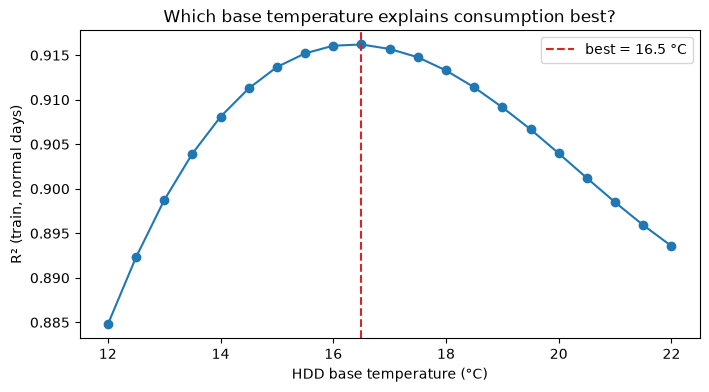

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hdd_scan.index, hdd_scan["R2"], marker="o")
ax.axvline(best, color="tab:red", ls="--", label=f"best = {best} °C")
ax.set_xlabel("HDD base temperature (°C)"); ax.set_ylabel("R² (train, normal days)")
ax.set_title("Which base temperature explains consumption best?"); ax.legend()
fig.savefig(FIG + "hdd_base_choice.png", dpi=150, bbox_inches="tight")

## Lesson 21 – Calendar features: Christmas period and bridge days

In [4]:
HDD_BASE = 16.5
df["hdd"] = np.maximum(0, HDD_BASE - df["temp_ch"])

# Christmas period: 24 Dec – 2 Jan (official holidays inside it stay marked by is_holiday too)
md = df.index.month * 100 + df.index.day          # e.g. 1224 = 24 Dec
df["christmas_period"] = ((md >= 1224) | (md <= 102)).astype(int)

# Bridge days: a weekday (Mon–Fri) that is not a holiday,
# with a holiday on one side and a weekend day on the other
hol = df["is_holiday"]
weekend = df["weekday"] >= 5
off_prev = (hol | weekend).shift(1, fill_value=False)   # yesterday off?
off_next = (hol | weekend).shift(-1, fill_value=False)  # tomorrow off?
hol_prev = hol.shift(1, fill_value=False)
hol_next = hol.shift(-1, fill_value=False)
df["bridge_day"] = (~weekend & ~hol
                    & ((hol_prev & off_next) | (hol_next & off_prev))).astype(int)

print("Christmas days:", df["christmas_period"].sum())
print("Bridge days:", df["bridge_day"].sum())
df.loc[df["bridge_day"] == 1].index.strftime("%a %d %b %Y")[:15]

Christmas days: 170
Bridge days: 36


Index(['Fri 02 Jan 2009', 'Fri 22 May 2009', 'Fri 14 May 2010',
       'Fri 03 Jun 2011', 'Mon 31 Oct 2011', 'Fri 18 May 2012',
       'Fri 02 Nov 2012', 'Mon 24 Dec 2012', 'Mon 31 Dec 2012',
       'Fri 10 May 2013', 'Fri 02 Aug 2013', 'Fri 27 Dec 2013',
       'Fri 30 May 2014', 'Fri 02 Jan 2015', 'Fri 15 May 2015'],
      dtype='str', name='date')

In [5]:
normal_wd = (df["weekday"] < 5) & ~df["is_holiday"]
check = pd.DataFrame({
    "normal weekday": df.loc[normal_wd & (df["bridge_day"] == 0) & (df["christmas_period"] == 0), "consumption_gwh"].mean(),
    "bridge day": df.loc[df["bridge_day"] == 1, "consumption_gwh"].mean(),
    "Christmas-period weekday (not holiday)": df.loc[normal_wd & (df["christmas_period"] == 1), "consumption_gwh"].mean(),
}, index=["mean GWh/day"]).T.round(1)
check

,mean GWh/day
normal weekday,162.2
bridge day,139.8
Christmas-period weekday (not holiday),159.4


In [6]:
winter = df.index.month.isin([12, 1])
compare = pd.DataFrame({
    "Dec/Jan weekday, outside Christmas period":
        df.loc[winter & normal_wd & (df["christmas_period"] == 0) & (df["bridge_day"] == 0), "consumption_gwh"].mean(),
    "Christmas-period weekday (not holiday, not bridge)":
        df.loc[normal_wd & (df["christmas_period"] == 1) & (df["bridge_day"] == 0), "consumption_gwh"].mean(),
}, index=["mean GWh/day"]).T.round(1)
compare

,mean GWh/day
"Dec/Jan weekday, outside Christmas period",188.4
"Christmas-period weekday (not holiday, not bridge)",159.9


## Lesson 22 – Lags, rolling mean, Fourier terms, and saving the dataset

In [7]:
y = df["consumption_gwh"]

# 1. lags of consumption (known before the forecast day)
for k in [1, 7, 364]:
    df[f"lag_{k}"] = y.shift(k)

# 2. 7-day rolling mean ending YESTERDAY (shift first → no leakage)
df["roll7_mean"] = y.shift(1).rolling(7).mean()

# 3. yesterday's HDD (thermal inertia of buildings)
df["hdd_lag1"] = df["hdd"].shift(1)

# 4. Fourier terms for the yearly cycle
t = np.arange(len(df))                     # day counter 0, 1, 2, ...
for k in range(1, 5):
    df[f"sin_{k}"] = np.sin(2 * np.pi * k * t / 365.25)
    df[f"cos_{k}"] = np.cos(2 * np.pi * k * t / 365.25)

print(df.shape)
print(df.isna().sum()[df.isna().sum() > 0])

(6209, 22)
lag_1           1
lag_7           7
lag_364       364
roll7_mean      7
hdd_lag1        1
dtype: int64


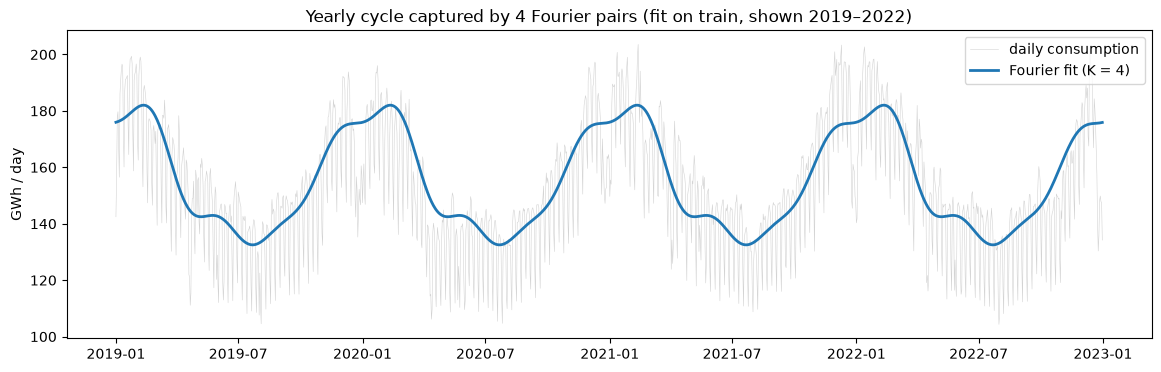

In [8]:
four_cols = [f"{f}_{k}" for k in range(1, 5) for f in ("sin", "cos")]
train_mask = df.index < "2023-01-01"
Xf = np.column_stack([np.ones(train_mask.sum()), df.loc[train_mask, four_cols].values])
coef, *_ = np.linalg.lstsq(Xf, y[train_mask].values, rcond=None)
yearly_fit = np.column_stack([np.ones(len(df)), df[four_cols].values]) @ coef

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(y["2019":"2022"], lw=0.4, color="lightgray", label="daily consumption")
ax.plot(df.index[(df.index >= "2019") & (df.index < "2023")],
        yearly_fit[(df.index >= "2019") & (df.index < "2023")], lw=2, label="Fourier fit (K = 4)")
ax.set_ylabel("GWh / day"); ax.legend(loc="upper right")
ax.set_title("Yearly cycle captured by 4 Fourier pairs (fit on train, shown 2019–2022)")
fig.savefig(FIG + "fourier_yearly_fit.png", dpi=150, bbox_inches="tight")

In [9]:
df.to_csv("../data/processed/dataset_features.csv", index_label="date")
check = pd.read_csv("../data/processed/dataset_features.csv", index_col="date", parse_dates=True)
print(check.shape, list(check.columns))

(6209, 22) ['consumption_gwh', 'temp_ch', 'holiday_share', 'is_holiday', 'weekday', 'month', 'hdd', 'christmas_period', 'bridge_day', 'lag_1', 'lag_7', 'lag_364', 'roll7_mean', 'hdd_lag1', 'sin_1', 'cos_1', 'sin_2', 'cos_2', 'sin_3', 'cos_3', 'sin_4', 'cos_4']


## Summary – Feature engineering

| Feature | How | Finding |
|---|---|---|
| `hdd` | max(0, 16.5 − temp) | Base chosen on train (R² 0.916, flat top 16–17 °C); ≈ 2.95 GWh per HDD |
| `christmas_period` | 24 Dec – 2 Jan | −28.5 GWh (−15 %) vs other Dec/Jan weekdays |
| `bridge_day` | weekday between a holiday and an off day | ~2/year; 139.8 GWh ≈ a Saturday (−22 GWh) |
| `lag_1`, `lag_7`, `lag_364` | past consumption | carry the current level (2022–23 break) |
| `roll7_mean` | 7-day mean ending yesterday | smooth recent level, no leakage |
| `hdd_lag1` | yesterday's HDD | thermal inertia of buildings |
| `sin_k`, `cos_k` (k = 1–4) | yearly Fourier terms | smooth yearly shape; must be paired with a level-tracking term |

All features are known before the forecast day (day-ahead task). Saved: `data/processed/dataset_features.csv` (6,209 × 22).